# 03 · Model Training, Threshold Selection & Evaluation

Uses the cleaned splits from notebook 02 and the 7-question feature set (`FINAL_SPEC`).

* Model selection and threshold choice use **training data only** (cross-validation / out-of-fold predictions).
* The **internal test set** (20%, stratified) is scored **once** at the end, standing in for the unseen hold-out.
* The production artifact is then refit on all labelled data with the same settings.

Positive class = **DECLINED** (the model outputs P(DECLINED)); decision rule: `DECLINE if P(DECLINED) ≥ threshold`.

In [1]:
import sys, json, time, warnings, platform
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import loguniform, randint, uniform
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve,
                             brier_score_loss, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

from loan_model import config as C
from loan_model.cleaning import target_to_int
from loan_model.modeling import FINAL_SPEC, build_pipeline, expected_cost_curve, ModelArtifact, timed_predict
from loan_model.predict import LoanScorer

sns.set_theme(style="whitegrid", palette="deep")
FIG = C.FIGURES_DIR
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight"); plt.show()

RAW_INPUTS = ["Pincode", "Age", "Employment_Type", "PAST_LOANS_ACTIVE", "Model_Description", "Loan_Amount", "LTV"]

In [2]:
train_df = pd.read_csv(C.PROCESSED_DIR / "train_clean.csv", dtype={"Pincode": str})
test_df = pd.read_csv(C.PROCESSED_DIR / "test_clean.csv", dtype={"Pincode": str})
# Lookup sources are passed at FIT time only, so FeatureBuilder can learn the pincode -> Final_Tier and
# Model_Description -> Make/Product/Variant maps. At scoring time (internal test, hold-out, chatbot) only
# RAW_INPUTS are given and those fields are derived from the pincode / vehicle model.
LOOKUP_SOURCES = ["Final_Tier", "Make_Code", "Product_Code", "Model_Variant"]
FIT_COLS = RAW_INPUTS + LOOKUP_SOURCES
X_tr, y_tr = train_df[FIT_COLS], target_to_int(train_df[C.TARGET])
X_te, y_te = test_df[RAW_INPUTS], target_to_int(test_df[C.TARGET])
print(f"train {X_tr.shape}, declined {y_tr.mean():.2%} | internal test {X_te.shape}, declined {y_te.mean():.2%}")
print("At scoring time the model only needs these raw inputs:", RAW_INPUTS)

train (86727, 11), declined 5.26% | internal test (21682, 7), declined 5.26%
At scoring time the model only needs these raw inputs: ['Pincode', 'Age', 'Employment_Type', 'PAST_LOANS_ACTIVE', 'Model_Description', 'Loan_Amount', 'LTV']


## 1. Candidate models (5-fold stratified CV on train)

In [3]:
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=C.RANDOM_STATE)
# Tree families compared head to head. Display name -> build_pipeline(model=...) key.
FAMILIES = {"HistGradientBoosting": "hgb", "Random forest": "rf", "XGBoost": "xgb", "LightGBM": "lgbm"}
candidates = {
    "Baseline: always APPROVE": DummyClassifier(strategy="most_frequent"),
    "Logistic regression (one-hot + target enc.)": build_pipeline(FINAL_SPEC, model="logreg"),
    "Logistic regression, class_weight=balanced": build_pipeline(FINAL_SPEC, model="logreg", class_weight="balanced"),
    **{f"{name} (default params)": build_pipeline(FINAL_SPEC, model=key) for name, key in FAMILIES.items()},
}

def cv_row(est):
    r = cross_validate(est, X_tr, y_tr, cv=CV5, scoring=["roc_auc", "average_precision", "neg_brier_score"], n_jobs=1)
    return {"ROC-AUC": r["test_roc_auc"].mean(), "ROC-AUC sd": r["test_roc_auc"].std(),
            "PR-AUC": r["test_average_precision"].mean(), "Brier": -r["test_neg_brier_score"].mean(),
            "fit s/fold": r["fit_time"].mean()}

cv_table = pd.DataFrame({name: cv_row(est) for name, est in candidates.items()}).T.rename_axis("model").round(4)
cv_table

,ROC-AUC,ROC-AUC sd,PR-AUC,Brier,fit s/fold
model,,,,,
Baseline: always APPROVE,0.5000,0.0000,0.0526,0.0526,0.0109
Logistic regression (one-hot + target enc.),0.7804,0.0074,0.1749,0.0465,0.8638
"Logistic regression, class_weight=balanced",0.7794,0.0069,0.1703,0.1981,0.9814
HistGradientBoosting (default params),0.7816,0.0074,0.1755,0.0465,1.3831
Random forest (default params),0.7784,0.0073,0.1739,0.0466,6.6438
XGBoost (default params),0.7837,0.0078,0.1790,0.0464,2.2519
LightGBM (default params),0.7812,0.0078,0.1739,0.0466,4.1250


PR-AUC is the more telling ranking metric at 5% prevalence: a random ranking gives PR-AUC ≈ 0.053, and the models get about 0.175 (3.3×).
All tree families beat logistic regression only slightly. The signal is dominated by LTV and region, which a linear model with
target-encoded geography already captures. With default settings XGBoost ranks best and random forest worst, but every gap is smaller than one fold standard deviation (~0.007).
`class_weight=balanced` does not improve ranking (AUC does not depend on the threshold) and ruins calibration (Brier 0.198 vs 0.047). We handle the
imbalance at the **threshold** instead, which keeps P(DECLINED) a usable probability.

## 2. Hyper-parameter tuning (every tree family, same budget)

Each family gets the same 20-trial randomised search on 3-fold CV, so the comparison is not biased toward the model we tuned most.

In [4]:
SEARCH_SPACES = {
    "hgb": {"clf__learning_rate": loguniform(0.02, 0.15), "clf__max_leaf_nodes": randint(8, 64),
            "clf__min_samples_leaf": randint(40, 400), "clf__l2_regularization": loguniform(0.01, 10),
            "clf__max_features": [0.5, 0.7, 1.0]},
    "rf": {"clf__n_estimators": [300, 500], "clf__min_samples_leaf": randint(20, 300),
           "clf__max_features": [0.3, 0.5, "sqrt"], "clf__max_depth": [None, 12, 20]},
    "xgb": {"clf__learning_rate": loguniform(0.01, 0.1), "clf__max_depth": randint(3, 8),
            "clf__min_child_weight": loguniform(1, 100), "clf__subsample": uniform(0.6, 0.4),
            "clf__colsample_bytree": uniform(0.5, 0.5), "clf__reg_lambda": loguniform(0.1, 20),
            "clf__n_estimators": randint(300, 1000)},
    "lgbm": {"clf__learning_rate": loguniform(0.01, 0.1), "clf__num_leaves": randint(8, 64),
             "clf__min_child_samples": randint(40, 400), "clf__subsample": uniform(0.6, 0.4),
             "clf__colsample_bytree": uniform(0.5, 0.5), "clf__reg_lambda": loguniform(0.1, 20),
             "clf__n_estimators": randint(300, 1000)},
}
best_params, search_summary = {}, []
for name, key in FAMILIES.items():
    # RF / XGBoost / LightGBM are multi-threaded internally, so the search itself runs serially.
    search = RandomizedSearchCV(build_pipeline(FINAL_SPEC, model=key), SEARCH_SPACES[key], n_iter=20, scoring="roc_auc",
                                cv=StratifiedKFold(3, shuffle=True, random_state=C.RANDOM_STATE),
                                random_state=C.RANDOM_STATE, n_jobs=4 if key == "hgb" else 1, refit=False)
    t0 = time.time(); search.fit(X_tr, y_tr)
    best_params[key] = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    search_summary.append({"model": name, "best 3-fold ROC-AUC": search.best_score_, "search s": time.time() - t0})
    print(f"{name:22s} best {search.best_score_:.4f}  {best_params[key]}")
pd.DataFrame(search_summary).set_index("model").round(4)

HistGradientBoosting   best 0.7816  {'l2_regularization': np.float64(0.2091498132903561), 'learning_rate': np.float64(0.025575311242654015), 'max_features': 0.5, 'max_leaf_nodes': 15, 'min_samples_leaf': 74}


Random forest          best 0.7773  {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 40, 'n_estimators': 300}


XGBoost                best 0.7829  {'colsample_bytree': np.float64(0.5370223258670452), 'learning_rate': np.float64(0.02282788775990513), 'max_depth': 3, 'min_child_weight': np.float64(67.59574377750826), 'n_estimators': 500, 'reg_lambda': np.float64(2.7178637804725723), 'subsample': np.float64(0.7323592099410596)}


LightGBM               best 0.7836  {'colsample_bytree': np.float64(0.5993578407670862), 'learning_rate': np.float64(0.010127963257331486), 'min_child_samples': 178, 'n_estimators': 798, 'num_leaves': 24, 'reg_lambda': np.float64(4.333304126829626), 'subsample': np.float64(0.9160702162124823)}


,best 3-fold ROC-AUC,search s
model,,
HistGradientBoosting,0.7816,57.8152
Random forest,0.7773,394.3682
XGBoost,0.7829,169.6484
LightGBM,0.7836,291.0868


In [5]:
for name, key in FAMILIES.items():
    cv_table.loc[f"{name} (tuned)"] = pd.Series(cv_row(build_pipeline(FINAL_SPEC, model=key, **best_params[key]))).round(4)
tree_rows = cv_table.loc[[i for i in cv_table.index if any(i.startswith(n) for n in FAMILIES)]]
tree_rows.sort_values("ROC-AUC", ascending=False)

,ROC-AUC,ROC-AUC sd,PR-AUC,Brier,fit s/fold
model,,,,,
LightGBM (tuned),0.7865,0.0075,0.1802,0.0463,5.2944
XGBoost (tuned),0.7853,0.0075,0.1802,0.0463,1.7688
HistGradientBoosting (tuned),0.7843,0.0071,0.1787,0.0464,1.9343
XGBoost (default params),0.7837,0.0078,0.1790,0.0464,2.2519
HistGradientBoosting (default params),0.7816,0.0074,0.1755,0.0465,1.3831
LightGBM (default params),0.7812,0.0078,0.1739,0.0466,4.1250
Random forest (default params),0.7784,0.0073,0.1739,0.0466,6.6438
Random forest (tuned),0.7781,0.0073,0.1737,0.0466,4.2955


In [6]:
# Pick the final model (family + default/tuned) by 5-fold CV ROC-AUC on train.
best_name = tree_rows["ROC-AUC"].idxmax()
FINAL_FAMILY = next(n for n in FAMILIES if best_name.startswith(n))
FINAL_MODEL = FAMILIES[FINAL_FAMILY]
FINAL_PARAMS = best_params[FINAL_MODEL] if best_name.endswith("(tuned)") else {}
print("Final model:", best_name, FINAL_PARAMS)

Final model: LightGBM (tuned) {'colsample_bytree': np.float64(0.5993578407670862), 'learning_rate': np.float64(0.010127963257331486), 'min_child_samples': 178, 'n_estimators': 798, 'num_leaves': 24, 'reg_lambda': np.float64(4.333304126829626), 'subsample': np.float64(0.9160702162124823)}


With equal tuning budgets, the boosted families converge: tuned LightGBM (0.7865), XGBoost (0.7853) and HistGradientBoosting (0.7843) all fall within one fold SD of each other.
Random forest does not gain from tuning and stays last (~0.778). The best configurations are all strongly regularised: shallow trees, slow learning rates and feature subsampling.
The rule picks the top CV ROC-AUC, which is **tuned LightGBM**. On the internal test set (section 4b) XGBoost and LightGBM are effectively tied, and both are ahead of HGB and RF.

## 3. Threshold selection (on out-of-fold training predictions)

The cut-off is a business trade-off:

* **False negative** – a risky applicant (should be DECLINED) is approved → credit loss.
* **False positive** – a good applicant is declined → lost margin / customer.

**Cost assumption.** The median loan is ≈ ₹90k.
* A risky applicant who is approved and goes bad loses roughly half the principal (two-wheelers resell poorly after
  repossession, and collection costs are high): ≈ ₹45k.
* A good two-wheeler loan earns a net margin of roughly 5% of principal over its tenure after funding and operating costs: ≈ ₹4.5k.

So **one wrongly approved risky applicant ≈ 10 wrongly declined good applicants** → `cost_fn = 10, cost_fp = 1`.
For calibrated probabilities the cost-minimising cut-off is about 1/(1+10) ≈ 0.09. We confirm it empirically on
out-of-fold predictions and show how the operating point moves if the ratio is different (sensitivity table).

In [7]:
oof = cross_val_predict(build_pipeline(FINAL_SPEC, model=FINAL_MODEL, **FINAL_PARAMS), X_tr, y_tr, cv=CV5, method="predict_proba")[:, 1]
print(f"OOF ROC-AUC {roc_auc_score(y_tr, oof):.4f} | PR-AUC {average_precision_score(y_tr, oof):.4f}")
COST_FN, COST_FP = 10.0, 1.0
curve = expected_cost_curve(y_tr, oof, cost_fn=COST_FN, cost_fp=COST_FP)
best_row = curve.loc[curve.cost.idxmin()]
THRESHOLD = float(best_row.threshold)
print(f"Cost-minimising threshold ({COST_FN:.0f}:1): {THRESHOLD}")
curve.iloc[::6].round(3)

OOF ROC-AUC 0.7863 | PR-AUC 0.1783
Cost-minimising threshold (10:1): 0.095


,threshold,tp,fp,fn,tn,decline_rate,recall_declined,precision_declined,recall_approved,precision_approved,accuracy,cost,cost_per_app
0,0.01,4455,62944,103,19225,0.777,0.977,0.066,0.234,0.995,0.273,63974.0,0.738
6,0.04,3685,32045,873,50124,0.412,0.808,0.103,0.610,0.983,0.620,40775.0,0.470
12,0.07,2883,18459,1675,63710,0.246,0.633,0.135,0.775,0.974,0.768,35209.0,0.406
18,0.10,2218,11173,2340,70996,0.154,0.487,0.166,0.864,0.968,0.844,34573.0,0.399
24,0.13,1679,6958,2879,75211,0.100,0.368,0.194,0.915,0.963,0.887,35748.0,0.412
30,0.16,1268,4428,3290,77741,0.066,0.278,0.223,0.946,0.959,0.911,37328.0,0.430
36,0.19,929,2853,3629,79316,0.044,0.204,0.246,0.965,0.956,0.925,39143.0,0.451
42,0.22,666,1822,3892,80347,0.029,0.146,0.268,0.978,0.954,0.934,40742.0,0.470
48,0.25,471,1101,4087,81068,0.018,0.103,0.300,0.987,0.952,0.940,41971.0,0.484
54,0.28,318,675,4240,81494,0.011,0.070,0.320,0.992,0.951,0.943,43075.0,0.497


In [8]:
sens = []
for ratio in [2, 3, 5, 8, 10, 15]:
    c = expected_cost_curve(y_tr, oof, cost_fn=ratio, cost_fp=1.0)
    b = c.loc[c.cost.idxmin()]
    sens.append({"cost_fn : cost_fp": f"{ratio}:1", "best threshold": b.threshold, "decline rate": b.decline_rate,
                 "recall DECLINED": b.recall_declined, "precision DECLINED": b.precision_declined,
                 "good customers lost (FP rate)": 1 - b.recall_approved})
pd.DataFrame(sens).round(3)

,cost_fn : cost_fp,best threshold,decline rate,recall DECLINED,precision DECLINED,good customers lost (FP rate)
0,2:1,0.340,0.004,0.027,0.390,0.002
1,3:1,0.265,0.015,0.087,0.312,0.011
2,5:1,0.160,0.066,0.278,0.223,0.054
3,8:1,0.110,0.133,0.442,0.174,0.116
4,10:1,0.095,0.167,0.510,0.161,0.148
5,15:1,0.060,0.291,0.694,0.125,0.269


**Chosen threshold: 0.095** (cost-minimising at 10:1, close to the theoretical 1/(1+10) ≈ 0.09 because the model is well calibrated).
On out-of-fold training predictions it catches **~51% of the risky (DECLINED) applicants** while declining ~15% of good applicants.
The overall decline rate is ~17%, against 5.3% historically.

The sensitivity table shows the trade-off clearly. A lender that values a lost customer more (5:1) would use ~0.16 and catch only ~28%
of risky applicants. A more conservative one (15:1) would use ~0.06 and catch ~69%, but decline over a quarter of good customers. The threshold is
a single number in the artifact (`models/loan_decision_model.json`), so risk management can change it without retraining.

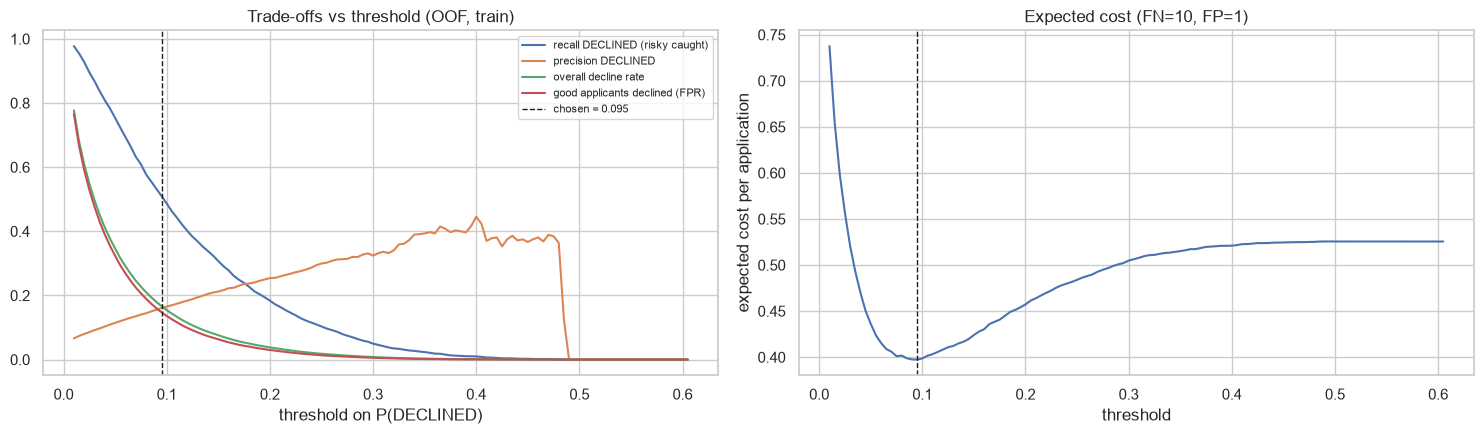

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(curve.threshold, curve.recall_declined, label="recall DECLINED (risky caught)")
ax[0].plot(curve.threshold, curve.precision_declined, label="precision DECLINED")
ax[0].plot(curve.threshold, curve.decline_rate, label="overall decline rate")
ax[0].plot(curve.threshold, 1 - curve.recall_approved, label="good applicants declined (FPR)")
ax[0].axvline(THRESHOLD, color="k", ls="--", lw=1, label=f"chosen = {THRESHOLD}")
ax[0].set_xlabel("threshold on P(DECLINED)"); ax[0].legend(fontsize=8); ax[0].set_title("Trade-offs vs threshold (OOF, train)")
ax[1].plot(curve.threshold, curve.cost_per_app); ax[1].axvline(THRESHOLD, color="k", ls="--", lw=1)
ax[1].set_xlabel("threshold"); ax[1].set_ylabel("expected cost per application"); ax[1].set_title(f"Expected cost (FN={COST_FN:.0f}, FP={COST_FP:.0f})")
savefig("12_threshold_selection")

## 4. Final fit on train → one-time evaluation on the internal test set

In [10]:
model = build_pipeline(FINAL_SPEC, model=FINAL_MODEL, **FINAL_PARAMS).fit(X_tr, y_tr)
p_te = model.predict_proba(X_te)[:, 1]

def threshold_metrics(y, p, t):
    pred = (p >= t).astype(int)
    return {
        "threshold": t,
        "accuracy": accuracy_score(y, pred),
        "precision_DECLINED": precision_score(y, pred, zero_division=0),
        "recall_DECLINED": recall_score(y, pred),
        "f1_DECLINED": f1_score(y, pred),
        "precision_APPROVED": precision_score(1 - y, 1 - pred, zero_division=0),
        "recall_APPROVED": recall_score(1 - y, 1 - pred),
        "f1_APPROVED": f1_score(1 - y, 1 - pred),
        "balanced_accuracy": (recall_score(y, pred) + recall_score(1 - y, 1 - pred)) / 2,
        "decline_rate": pred.mean(),
    }

ranking = {"ROC-AUC": roc_auc_score(y_te, p_te), "PR-AUC": average_precision_score(y_te, p_te),
           "Brier": brier_score_loss(y_te, p_te), "PR-AUC of random model": y_te.mean()}
print("Threshold-free ranking metrics (internal test):"); display(pd.Series(ranking).round(4).to_frame("value"))
tm = pd.DataFrame([threshold_metrics(y_te, p_te, THRESHOLD), threshold_metrics(y_te, p_te, 0.5)],
                  index=[f"chosen threshold {THRESHOLD}", "naive threshold 0.5"]).T
tm.round(4)

Threshold-free ranking metrics (internal test):


,value
ROC-AUC,0.7890
PR-AUC,0.1893
Brier,0.0461
PR-AUC of random model,0.0526


,chosen threshold 0.095,naive threshold 0.5
threshold,0.0950,0.5000
accuracy,0.8335,0.9474
precision_DECLINED,0.1564,0.0000
recall_DECLINED,0.4930,0.0000
f1_DECLINED,0.2374,0.0000
precision_APPROVED,0.9680,0.9474
recall_APPROVED,0.8524,1.0000
f1_APPROVED,0.9065,0.9730
balanced_accuracy,0.6727,0.5000
decline_rate,0.1658,0.0000


**Accuracy is misleading here.** The naive 0.5 threshold scores 94.7% accuracy by approving everyone (0 risky applicants caught).
At the chosen threshold accuracy drops to ~82% but **recall on DECLINED rises from 0% to ~51%**, which is the business objective.

              precision    recall  f1-score   support

    APPROVED     0.9680    0.8524    0.9065     20542
    DECLINED     0.1564    0.4930    0.2374      1140

    accuracy                         0.8335     21682
   macro avg     0.5622    0.6727    0.5720     21682
weighted avg     0.9254    0.8335    0.8714     21682



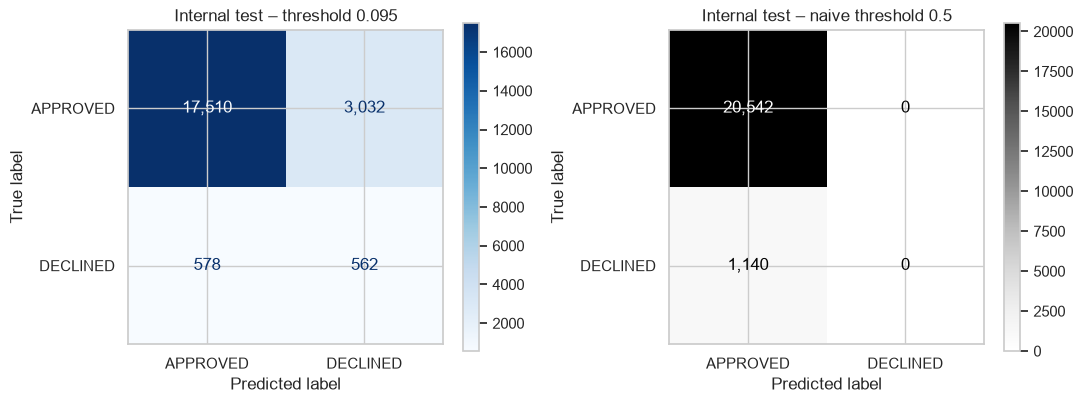

In [11]:
pred_te = (p_te >= THRESHOLD).astype(int)
print(classification_report(y_te, pred_te, target_names=["APPROVED", "DECLINED"], digits=4))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=["APPROVED", "DECLINED"]).plot(ax=ax[0], cmap="Blues", values_format=",")
ax[0].set_title(f"Internal test – threshold {THRESHOLD}")
ConfusionMatrixDisplay(confusion_matrix(y_te, (p_te >= 0.5).astype(int)), display_labels=["APPROVED", "DECLINED"]).plot(ax=ax[1], cmap="Greys", values_format=",")
ax[1].set_title("Internal test – naive threshold 0.5")
savefig("13_confusion_matrices")

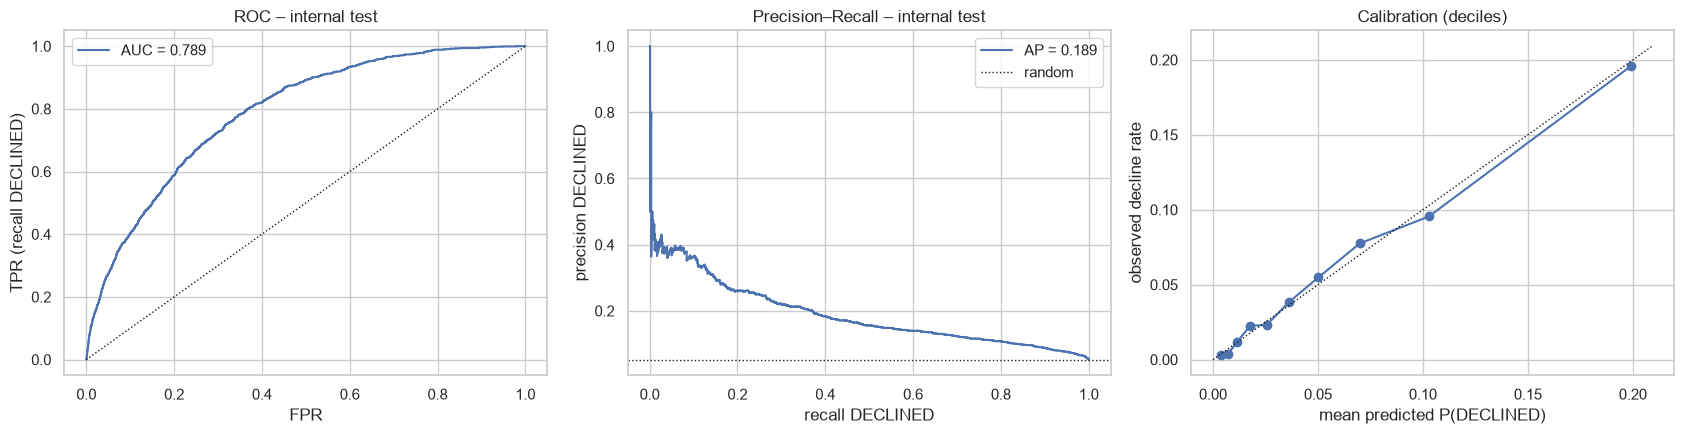

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[0].plot(fpr, tpr, label=f"AUC = {ranking['ROC-AUC']:.3f}"); ax[0].plot([0, 1], [0, 1], "k:", lw=1)
ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR (recall DECLINED)"); ax[0].set_title("ROC – internal test"); ax[0].legend()
pr, rc, _ = precision_recall_curve(y_te, p_te)
ax[1].plot(rc, pr, label=f"AP = {ranking['PR-AUC']:.3f}"); ax[1].axhline(y_te.mean(), color="k", ls=":", lw=1, label="random")
ax[1].set_xlabel("recall DECLINED"); ax[1].set_ylabel("precision DECLINED"); ax[1].set_title("Precision–Recall – internal test"); ax[1].legend()
frac, mean_p = calibration_curve(y_te, p_te, n_bins=10, strategy="quantile")
ax[2].plot(mean_p, frac, marker="o"); lim = max(mean_p.max(), frac.max()) * 1.05; ax[2].plot([0, lim], [0, lim], "k:", lw=1)
ax[2].set_xlabel("mean predicted P(DECLINED)"); ax[2].set_ylabel("observed decline rate"); ax[2].set_title("Calibration (deciles)")
savefig("14_roc_pr_calibration")

In [13]:
dec = pd.DataFrame({"p": p_te, "y": y_te})
dec["risk_decile"] = pd.qcut(dec.p.rank(method="first"), 10, labels=range(1, 11))
lift = dec.groupby("risk_decile", observed=True).agg(n=("y", "size"), mean_score=("p", "mean"), declined_rate=("y", "mean"), declined=("y", "sum"))
lift["share_of_all_declined"] = lift.declined / lift.declined.sum()
lift["lift"] = lift.declined_rate / y_te.mean()
print("Risk deciles (10 = riskiest) – internal test"); lift.round(3)

Risk deciles (10 = riskiest) – internal test


,n,mean_score,declined_rate,declined,share_of_all_declined,lift
risk_decile,,,,,,
1,2169,0.004,0.003,6,0.005,0.053
2,2168,0.007,0.004,8,0.007,0.070
3,2168,0.011,0.012,25,0.022,0.219
4,2168,0.018,0.023,49,0.043,0.430
5,2168,0.026,0.023,50,0.044,0.439
6,2168,0.036,0.038,83,0.073,0.728
7,2168,0.050,0.055,119,0.104,1.044
8,2168,0.070,0.077,168,0.147,1.474
9,2168,0.103,0.095,207,0.182,1.816


The ranking is useful: the riskiest 10% of applicants contain **37% of all declines** (lift 3.7×), and the safest 30% contain
under 4%. Predicted and observed decline rates agree in every decile, so the model is well calibrated (see also the calibration plot).

## 4b. Model comparison on the internal test set (for information)

Every tuned family is refit on train and scored on the internal test set, at the same cost-based threshold.
The choice above was made on CV only, so this table does not feed back into selection; it shows how the families compare on unseen rows.

In [14]:
comp_rows, comp_scores = [], {}
for name, key in FAMILIES.items():
    t0 = time.time(); est = build_pipeline(FINAL_SPEC, model=key, **best_params[key]).fit(X_tr, y_tr); fit_s = time.time() - t0
    p = est.predict_proba(X_te)[:, 1]; comp_scores[name] = p
    t0 = time.perf_counter(); est.predict_proba(X_te.iloc[:1]); one_ms = (time.perf_counter() - t0) * 1000
    tmx = threshold_metrics(y_te, p, THRESHOLD)
    comp_rows.append({"model": f"{name} (tuned)", "ROC-AUC": roc_auc_score(y_te, p), "PR-AUC": average_precision_score(y_te, p),
                      "Brier": brier_score_loss(y_te, p), f"recall DECLINED @{THRESHOLD}": tmx["recall_DECLINED"],
                      f"precision DECLINED @{THRESHOLD}": tmx["precision_DECLINED"], "decline rate": tmx["decline_rate"],
                      "fit s": fit_s, "1-row predict ms": one_ms})
comparison = pd.DataFrame(comp_rows).set_index("model").sort_values("ROC-AUC", ascending=False)
comparison.round(4)

,ROC-AUC,PR-AUC,Brier,recall DECLINED @0.095,precision DECLINED @0.095,decline rate,fit s,1-row predict ms
model,,,,,,,,
XGBoost (tuned),0.7893,0.1865,0.0462,0.5018,0.1596,0.1653,2.4099,16.9652
LightGBM (tuned),0.7890,0.1893,0.0461,0.4930,0.1564,0.1658,6.8241,20.0113
HistGradientBoosting (tuned),0.7858,0.1835,0.0463,0.4798,0.1539,0.1640,2.4558,44.1135
Random forest (tuned),0.7809,0.1792,0.0464,0.5193,0.1563,0.1747,6.8294,55.8843


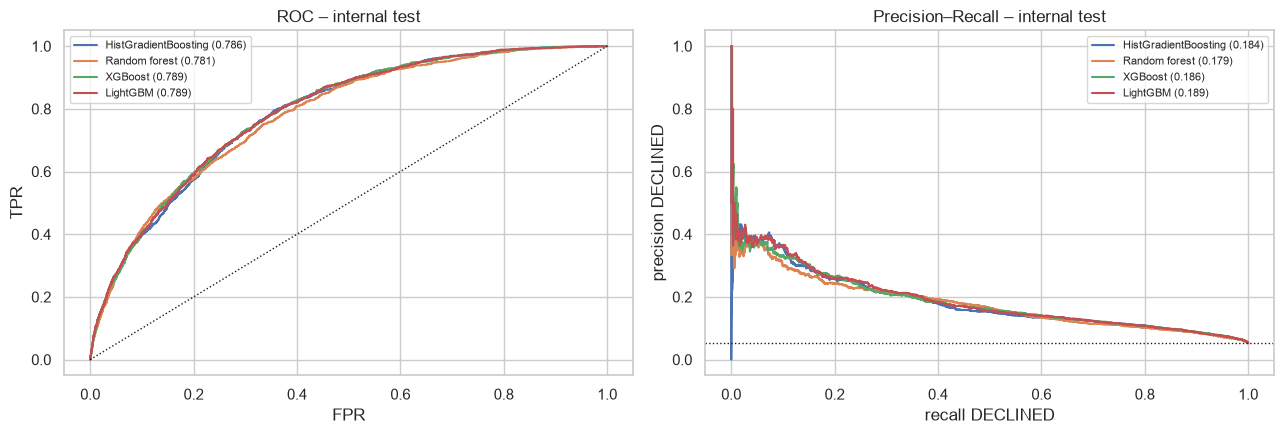

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, p in comp_scores.items():
    fpr, tpr, _ = roc_curve(y_te, p); ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p); ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(y_te, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].set_title("ROC – internal test"); ax[0].legend(fontsize=8)
ax[1].axhline(y_te.mean(), color="k", ls=":", lw=1); ax[1].set_xlabel("recall DECLINED"); ax[1].set_ylabel("precision DECLINED")
ax[1].set_title("Precision–Recall – internal test"); ax[1].legend(fontsize=8)
savefig("16_model_comparison")

## 5. What drives the model? (permutation importance, internal test)

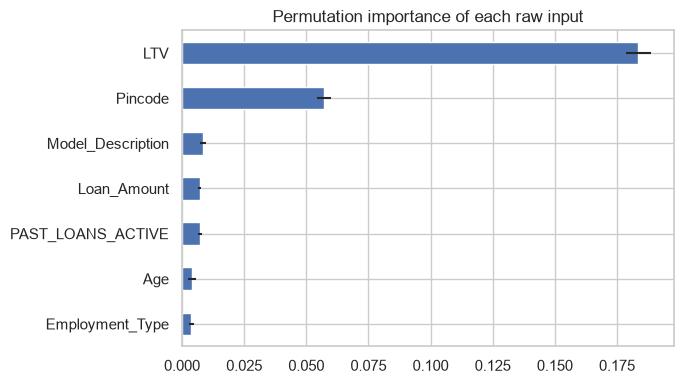

,AUC drop when shuffled,sd
Employment_Type,0.0037,0.0010
Age,0.0041,0.0015
PAST_LOANS_ACTIVE,0.0071,0.0008
Loan_Amount,0.0071,0.0006
Model_Description,0.0085,0.0013
Pincode,0.0572,0.0029
LTV,0.1835,0.0050


In [16]:
pi = permutation_importance(model, X_te, y_te, scoring="roc_auc", n_repeats=5, random_state=C.RANDOM_STATE, n_jobs=4)
imp = pd.DataFrame({"AUC drop when shuffled": pi.importances_mean, "sd": pi.importances_std}, index=RAW_INPUTS).sort_values("AUC drop when shuffled")
ax = imp["AUC drop when shuffled"].plot.barh(xerr=imp.sd, figsize=(7, 4), title="Permutation importance of each raw input")
savefig("15_permutation_importance"); imp.round(4)

LTV dominates, followed by location (pincode). The vehicle model, past loans, loan amount, age and employment type each add
a little, consistent with the ablation in notebook 02. Every one of the 7 inputs has a positive, non-trivial importance.

## 6. Robustness: missing and unseen inputs
The brief warns that the hold-out set may contain categories not seen in training. The pipeline must never fail on them.

In [17]:
edge = pd.DataFrame([
    {"Pincode": "999999", "Age": "30", "Employment_Type": "ASTRONAUT", "PAST_LOANS_ACTIVE": "NO_PAST_LOANS",
     "Model_Description": "TVS BRAND NEW MODEL 2027", "Loan_Amount": "90000", "LTV": "80"},   # unseen everything
    {"Pincode": None, "Age": None, "Employment_Type": None, "PAST_LOANS_ACTIVE": None,
     "Model_Description": None, "Loan_Amount": "90000", "LTV": None},                         # mostly missing
    {"Pincode": "abc", "Age": " ", "Employment_Type": "sal", "PAST_LOANS_ACTIVE": "past_loans_active",
     "Model_Description": "ntorq 125 disc â€“ race edition bsvi", "Loan_Amount": "110000", "LTV": "0"},  # dirty input
])
from loan_model.cleaning import clean_raw
edge_scores = model.predict_proba(clean_raw(edge))[:, 1]
edge.assign(P_DECLINED=edge_scores.round(4))

,Pincode,Age,Employment_Type,PAST_LOANS_ACTIVE,Model_Description,Loan_Amount,LTV,P_DECLINED
0,999999,30,ASTRONAUT,NO_PAST_LOANS,TVS BRAND NEW MODEL 2027,90000,80,0.0373
1,NaN,NaN,NaN,NaN,NaN,90000,NaN,0.0476
2,abc,,sal,past_loans_active,ntorq 125 disc â€“ race edition bsvi,110000,0,0.0634


Unseen pincodes, employment types and vehicle models, blank or garbage values, lower-case text and mojibake are all handled.
The pipeline returns a probability instead of failing.

## 7. Decision latency
Measured end-to-end for **one application**: raw dict → cleaning → feature engineering → encoding → model → decision.

In [18]:
tmp_art = ModelArtifact(model, THRESHOLD, RAW_INPUTS)
tmp_path = C.MODELS_DIR / "_tmp_latency.joblib"; tmp_art.save(tmp_path)
scorer = LoanScorer(tmp_path)
apps = X_te.sample(300, random_state=1).to_dict(orient="records")
scorer.score_application(apps[0])  # warm-up
lat = np.array([scorer.score_application(a).latency_ms for a in apps])
tmp_path.unlink(); tmp_path.with_suffix(".json").unlink()
latency = {"p50_ms": np.percentile(lat, 50), "p95_ms": np.percentile(lat, 95), "p99_ms": np.percentile(lat, 99), "max_ms": lat.max()}
print(f"Machine: {platform.machine()} / {platform.processor() or platform.platform()}")
pd.Series(latency).round(2).to_frame("single-application latency")

Machine: arm64 / arm


,single-application latency
p50_ms,11.09
p95_ms,12.67
p99_ms,14.12
max_ms,15.40


**Latency (Y).** Scoring one application end to end takes ≈ 11 ms at the median and < 15 ms at p99 on a laptop CPU. We commit to
**Y ≤ 1 second** from final input to decision. That leaves more than 15× headroom for logging, network and the chatbot response layer, and is
well below the point at which a user notices a delay.

## 8. Production artifact
Settings (features, hyper-parameters, threshold) are frozen from the steps above. The production model is **refit on all
labelled data** (train + internal test) so the hold-out predictions benefit from 25% more data; the metrics reported above
come from the train-only model, so they are an honest estimate of hold-out performance.

In [19]:
full_df = pd.concat([train_df, test_df], ignore_index=True)
prod_model = build_pipeline(FINAL_SPEC, model=FINAL_MODEL, **FINAL_PARAMS).fit(full_df[FIT_COLS], target_to_int(full_df[C.TARGET]))

metrics = {
    "internal_test_ranking": {k: round(float(v), 4) for k, v in ranking.items()},
    "internal_test_at_threshold": {k: round(float(v), 4) for k, v in threshold_metrics(y_te, p_te, THRESHOLD).items()},
    "internal_test_confusion_matrix": {"labels": ["APPROVED", "DECLINED"], "matrix": confusion_matrix(y_te, pred_te).tolist()},
    "cv5_train": cv_table.reset_index().round(4).to_dict(orient="records"),
    "internal_test_model_comparison": comparison.reset_index().round(4).to_dict(orient="records"),
    "latency_ms": {k: round(float(v), 2) for k, v in latency.items()},
}
artifact = ModelArtifact(
    pipeline=prod_model, threshold=THRESHOLD, raw_input_fields=RAW_INPUTS,
    metadata={
        "model": type(prod_model.named_steps["clf"]).__name__, "model_family": FINAL_FAMILY, "hyperparameters": {k: (float(v) if isinstance(v, (np.floating, float)) else int(v) if isinstance(v, (np.integer, int)) else v) for k, v in FINAL_PARAMS.items()},
        "feature_spec": {"numeric": FINAL_SPEC.numeric, "low_card": FINAL_SPEC.low_card, "high_card": FINAL_SPEC.high_card},
        "positive_class": "DECLINED", "decision_rule": f"DECLINED if P(DECLINED) >= {THRESHOLD}",
        "cost_assumption": {"cost_fn_risky_approved": COST_FN, "cost_fp_good_declined": COST_FP},
        "trained_on_rows": len(full_df), "sklearn_version": sklearn.__version__,
        "trained_at": pd.Timestamp.now().isoformat(timespec="seconds"),
        "metrics": metrics,
    },
)
path = artifact.save()
(C.REPORTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
test_df[[C.ID_COL]].assign(P_DECLINED=p_te.round(6), Predicted=np.where(pred_te == 1, "DECLINED", "APPROVED"),
                           Actual=test_df[C.TARGET]).to_csv(C.REPORTS_DIR / "internal_test_predictions.csv", index=False)
print("saved", path.relative_to(ROOT), "and", path.with_suffix(".json").relative_to(ROOT))

saved models/loan_decision_model.joblib and models/loan_decision_model.json


In [20]:
# Smoke test: reload the artifact exactly as the chatbot / hold-out script will
scorer = LoanScorer()
example = {"Pincode": "560068", "Age": 29, "Employment_Type": "SAL", "PAST_LOANS_ACTIVE": "NO_PAST_LOANS",
           "Model_Description": "TVS RAIDER DISC BSVI", "Loan_Amount": 95000, "LTV": 88.5}
scorer.score_application(example)

Decision(decision='DECLINED', p_declined=0.118402, threshold=0.095, latency_ms=17.35, features={'tier_ord': 2.0, 'pin2': '56', 'pin3': '560', 'pincode': '560068', 'Make_Code': 'RAIDER', 'Product_Code': 'MC', 'Model_Variant': 'RAIDER', 'Model_Description': 'TVS RAIDER DISC BSVI', 'Loan_Amount': 95000.0, 'LTV': 88.5, 'Net_salary': nan, 'vehicle_value': 107344.63276836158, 'down_payment': 12344.632768361582, 'loan_to_income': nan, 'salary_missing': 1, 'ltv_missing': 0, 'Age': 29.0, 'Employment_Type': 'SAL', 'PAST_LOANS_ACTIVE': 'NO_PAST_LOANS'})